<a href="https://colab.research.google.com/github/hafisc/254107023005_pcvk_2026/blob/main/Pertemuan%2010/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modul 10 - Dasar-Dasar Deteksi Objek
**Mata Kuliah: Pengolahan Citra dan Visi Komputer**  
**Jurusan Teknologi Informasi - Politeknik Negeri Malang**

---
- **Nama** : Mohammad Al Hafis Hidayatulloh
- **NIM**  : 254107023005
- **Kelas**: TI-3G

In [1]:
# Mount Google Drive jika dijalankan di Colab
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    # Folder pertemuan 10 di Google Drive
    BASE = '/content/drive/MyDrive/pcvk_2026/pertemuan 10/'
except ImportError:
    # Jika running lokal di folder praktikum
    BASE = './' if os.path.exists('Images Object Detection') else \
           'E:/Dokumen/Kuliah/Semester 5/Pengantar Citra Digital dan Visi Komputer/Pertemuan 10/'

PATH    = BASE + 'Images Object Detection/'   # citra praktikum D1
FACEDET = PATH + 'facedet/'                    # citra face detection (/Images/facedet)
KTM_DIR = BASE + 'KTM/'                        # foto KTM (soal 14 & D3)

print("Path dataset :", PATH)
print("Path facedet :", FACEDET)
print("Path KTM     :", KTM_DIR)
print("Isi facedet  :", sorted(os.listdir(FACEDET)))
print("Isi KTM      :", sorted(os.listdir(KTM_DIR)) if os.path.exists(KTM_DIR) else 'folder KTM belum ada')

Mounted at /content/drive
Path dataset : /content/drive/MyDrive/pcvk_2026/pertemuan 10/Images Object Detection/
Path facedet : /content/drive/MyDrive/pcvk_2026/pertemuan 10/Images Object Detection/facedet/
Path KTM     : /content/drive/MyDrive/pcvk_2026/pertemuan 10/KTM/
Isi facedet  : ['jokowi.jpg', 'kartini.jpg', 'kucing.jpg', 'many_cereals.jpg', 'mask.png', 'mjordan.jpg', 'people.jpg', 'reeses_puffs.png', 'solvayconf.jpg']
Isi KTM      : ['foto_ktm.jpg', 'ktm_benda.jpeg', 'ktm_flash.jpeg', 'ktm_gelap.jpeg', 'ktm_ruang.jpeg', 'ktm_terang.jpeg']


In [2]:
import sys, subprocess
from importlib import metadata

# Colab terbaru memakai OpenCV 5.x. Di OpenCV 5, Haar cascade (CascadeClassifier)
# tidak lagi ada di modul utama, padahal praktikum ini memakai API OpenCV 4.x.
# Jika terdeteksi OpenCV >= 5, versi dikunci ke 4.x sebelum cv2 di-import.
paket_cv5 = sorted({d.metadata['Name'] for d in metadata.distributions()
                    if (d.metadata['Name'] or '').lower().startswith('opencv')
                    and int(d.version.split('.')[0]) >= 5})
if paket_cv5:
    print("OpenCV 5.x terdeteksi -> install OpenCV 4.x:", paket_cv5)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + [p + '<5' for p in paket_cv5], check=True)
    if 'cv2' in sys.modules:
        # cv2 versi 5 sudah terlanjur di-import di sesi ini -> runtime harus restart
        print("Runtime akan restart. Setelah itu jalankan ulang: Runtime > Jalankan semua.")
        os.kill(os.getpid(), 9)

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv.__version__)
print("NumPy Version :", np.__version__)
assert hasattr(cv, 'CascadeClassifier'), "OpenCV tidak memiliki CascadeClassifier, restart runtime lalu jalankan ulang."

OpenCV Version: 5.0.0
NumPy Version : 2.4.6


---
## D1. Praktikum Deteksi Objek Dasar

### Soal 2: Template Matching 6 Metode OpenCV
Mencari posisi template `cat2_templatejpg.jpg` pada citra `cats_and_bunnies.jpg` menggunakan 6 metode yang disediakan OpenCV.

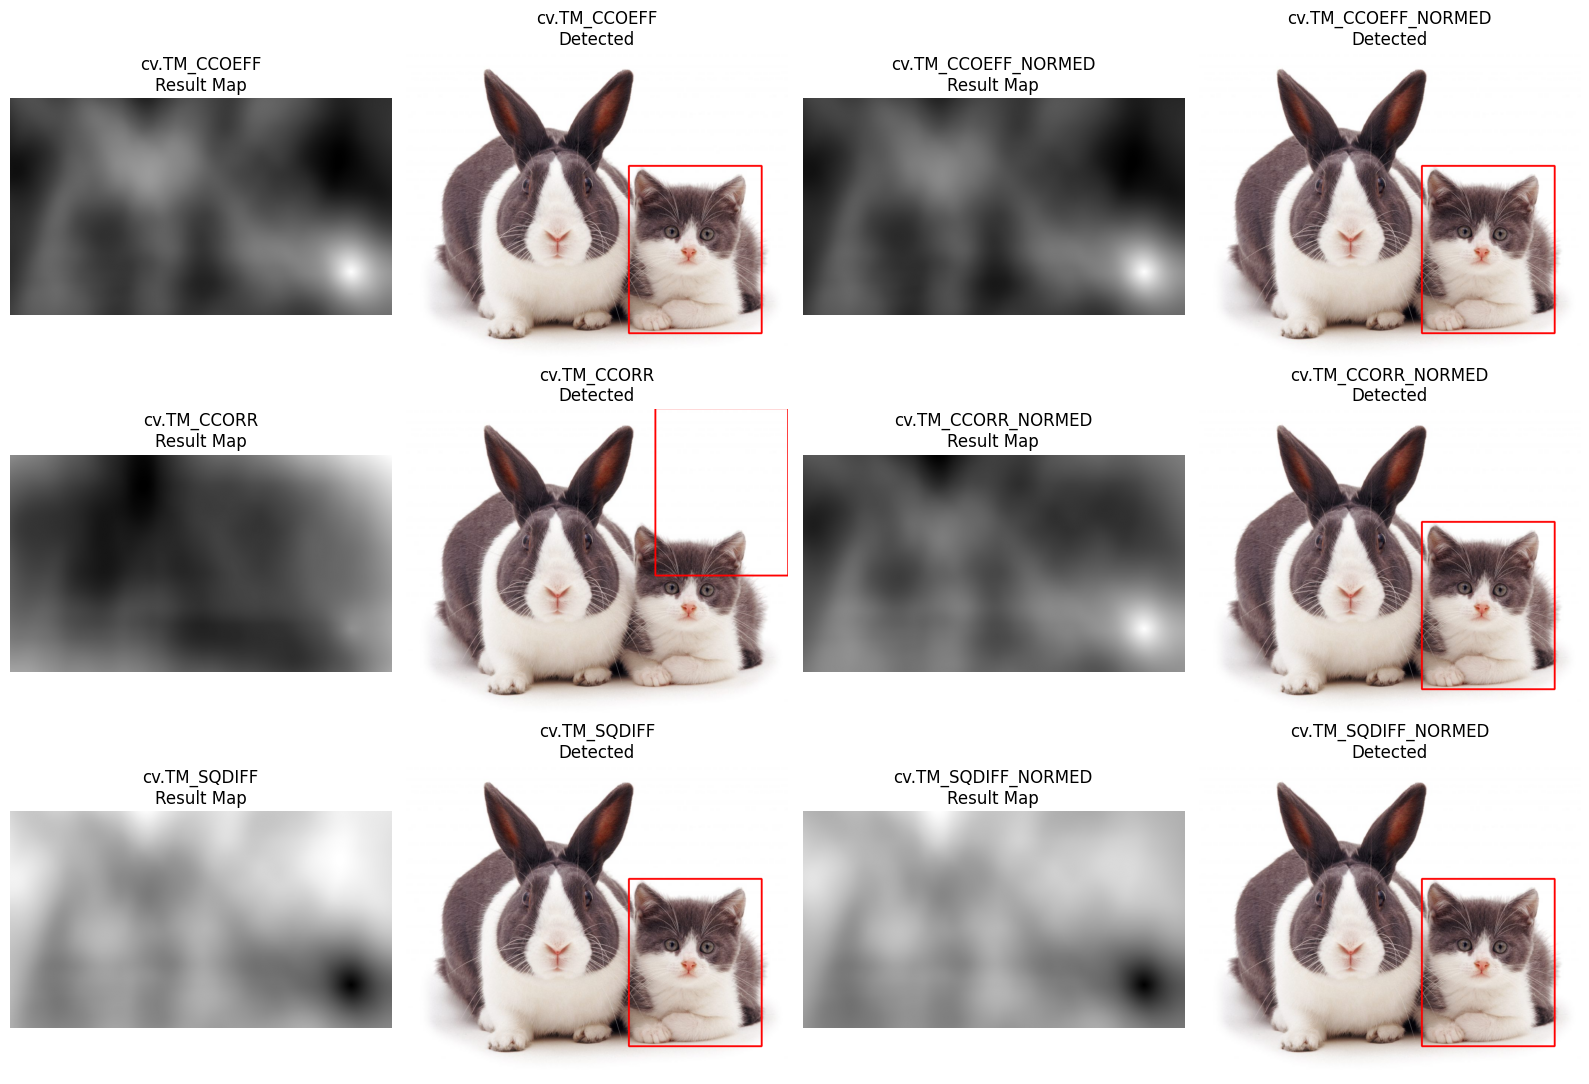

In [3]:
img_bgr = cv.imread(PATH + 'cats_and_bunnies.jpg')
template = cv.imread(PATH + 'cat2_templatejpg.jpg')

img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

h, w = template_gray.shape

# Daftar 6 metode template matching di OpenCV
methods = [
    'cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED',
    'cv.TM_CCORR', 'cv.TM_CCORR_NORMED',
    'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED'
]

plt.figure(figsize=(16, 11))

for i, meth in enumerate(methods):
    img = img_bgr.copy()
    method = eval(meth)

    # Terapkan template matching
    res = cv.matchTemplate(img_gray, template_gray, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # Untuk SQDIFF dan SQDIFF_NORMED nilai terbaik adalah nilai minimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)

    # Gambar kotak merah pada objek terdeteksi
    cv.rectangle(img, top_left, bottom_right, (0, 0, 255), 3)

    # Tampilkan map hasil matching
    plt.subplot(3, 4, 2*i + 1)
    plt.imshow(res, cmap='gray')
    plt.title(f'{meth}\nResult Map')
    plt.axis('off')

    # Tampilkan hasil deteksi pada gambar
    plt.subplot(3, 4, 2*i + 2)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(f'{meth}\nDetected')
    plt.axis('off')

plt.tight_layout()
plt.show()

### Soal 3: Template Matching Manual (Multiple Object)
Mengimplementasikan konsep template matching secara manual tanpa fungsi `cv.matchTemplate()` untuk mendeteksi multiple object pada gambar `bahrain.jpg` menggunakan template `bahrain-template.jpg`.

Ukuran gambar   : 586 x 596
Ukuran template : 73 x 88
Kandidat >= threshold : 332 piksel
Objek setelah NMS     : 6


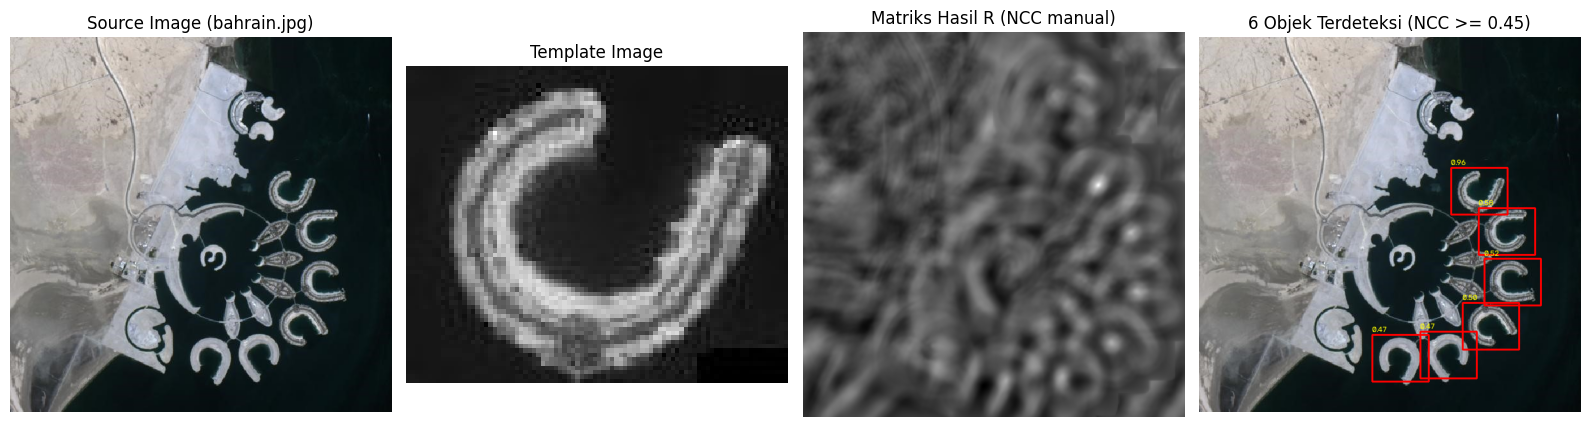

In [4]:
# Load citra input dan citra template
bahrain = cv.imread(PATH + 'bahrain.jpg')
bahrain_gray = cv.cvtColor(bahrain, cv.COLOR_BGR2GRAY).astype(np.float32)

template_car = cv.imread(PATH + 'bahrain-template.jpg', 0).astype(np.float32)

H, W = bahrain_gray.shape
h, w = template_car.shape

print(f"Ukuran gambar   : {H} x {W}")
print(f"Ukuran template : {h} x {w}")

# Normalisasi template terlebih dahulu
tmpl_mean = np.mean(template_car)
tmpl_diff = template_car - tmpl_mean
tmpl_norm = np.linalg.norm(tmpl_diff)

# Matriks untuk menyimpan nilai korelasi
res_manual = np.zeros((H - h + 1, W - w + 1), dtype=np.float32)

# Perulangan sliding window untuk menghitung Normalized Cross-Correlation (NCC)
for y in range(H - h + 1):
    for x in range(W - w + 1):
        patch = bahrain_gray[y:y+h, x:x+w]
        patch_diff = patch - np.mean(patch)
        patch_norm = np.linalg.norm(patch_diff)

        if patch_norm > 0 and tmpl_norm > 0:
            res_manual[y, x] = np.sum(patch_diff * tmpl_diff) / (patch_norm * tmpl_norm)

# Ambang batas korelasi untuk mendeteksi objek (pulau berbentuk C)
threshold = 0.45
ys, xs = np.where(res_manual >= threshold)
skor = res_manual[ys, xs]

# Non-Maximum Suppression manual: ambil skor tertinggi lebih dulu,
# lalu buang kandidat lain yang posisinya terlalu dekat (objek yang sama)
deteksi = []
for i in np.argsort(-skor):
    x, y = xs[i], ys[i]
    if all(abs(x - dx) > w // 2 or abs(y - dy) > h // 2 for dx, dy, _ in deteksi):
        deteksi.append((x, y, skor[i]))

print(f"Kandidat >= threshold : {len(xs)} piksel")
print(f"Objek setelah NMS     : {len(deteksi)}")

# Gambar kotak merah pada setiap objek terdeteksi
hasil_bahrain = bahrain.copy()
for (x, y, s) in deteksi:
    cv.rectangle(hasil_bahrain, (int(x), int(y)), (int(x) + w, int(y) + h), (0, 0, 255), 2)
    cv.putText(hasil_bahrain, f'{s:.2f}', (int(x), int(y) - 4), cv.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)

# Tampilkan hasil
plt.figure(figsize=(16, 5.5))

plt.subplot(1, 4, 1)
plt.imshow(cv.cvtColor(bahrain, cv.COLOR_BGR2RGB))
plt.title('Source Image (bahrain.jpg)')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(template_car, cmap='gray')
plt.title('Template Image')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(res_manual, cmap='gray')
plt.title('Matriks Hasil R (NCC manual)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(cv.cvtColor(hasil_bahrain, cv.COLOR_BGR2RGB))
plt.title(f'{len(deteksi)} Objek Terdeteksi (NCC >= {threshold})')
plt.axis('off')

plt.tight_layout()
plt.show()

### Soal 4: Edge Detection (Sobel, Canny, Laplacian)
Menguji ketiga metode deteksi tepi pada citra `car-park.jpg`.

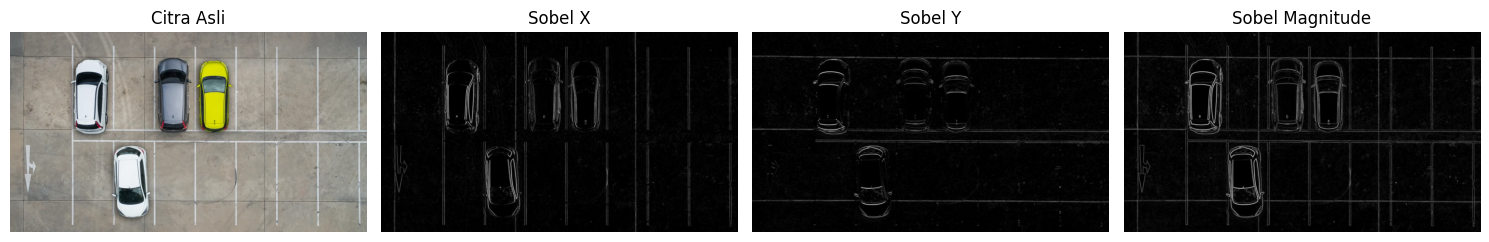

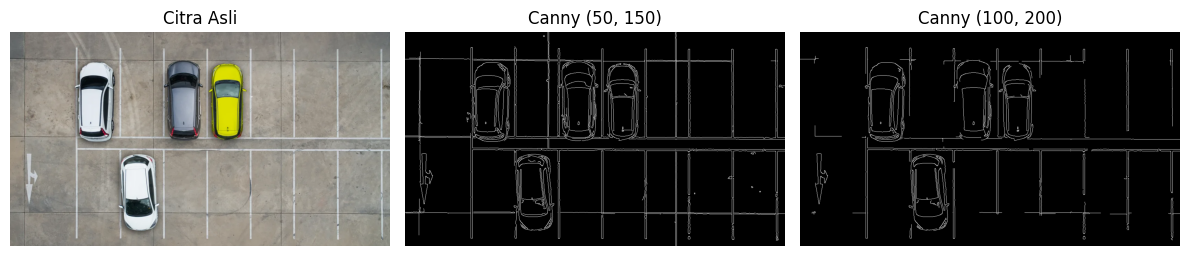

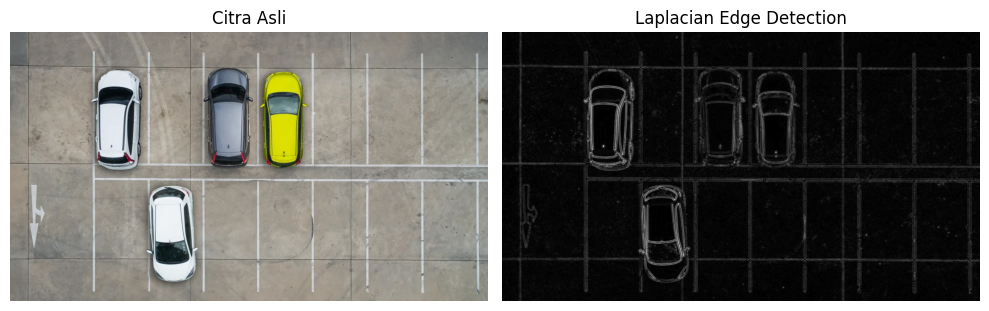

In [5]:
car = cv.imread(PATH + 'car-park.jpg')
car_gray = cv.cvtColor(car, cv.COLOR_BGR2GRAY)

# a. Sobel Edge Detection
sobelx = cv.Sobel(car_gray, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(car_gray, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobelx, sobely)

plt.figure(figsize=(15, 4))
plt.subplot(1, 4, 1), plt.imshow(cv.cvtColor(car, cv.COLOR_BGR2RGB)), plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 4, 2), plt.imshow(np.abs(sobelx), cmap='gray'), plt.title('Sobel X'), plt.axis('off')
plt.subplot(1, 4, 3), plt.imshow(np.abs(sobely), cmap='gray'), plt.title('Sobel Y'), plt.axis('off')
plt.subplot(1, 4, 4), plt.imshow(sobel_combined, cmap='gray'), plt.title('Sobel Magnitude'), plt.axis('off')
plt.tight_layout()
plt.show()

# b. Canny Edge Detection (dengan filter Gaussian terlebih dahulu)
blur = cv.GaussianBlur(car_gray, (5, 5), 0)
canny_1 = cv.Canny(blur, 50, 150)
canny_2 = cv.Canny(blur, 100, 200)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(cv.cvtColor(car, cv.COLOR_BGR2RGB)), plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(canny_1, cmap='gray'), plt.title('Canny (50, 150)'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(canny_2, cmap='gray'), plt.title('Canny (100, 200)'), plt.axis('off')
plt.tight_layout()
plt.show()

# c. Laplacian Edge Detection
laplacian = cv.Laplacian(blur, cv.CV_64F)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1), plt.imshow(cv.cvtColor(car, cv.COLOR_BGR2RGB)), plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(np.abs(laplacian), cmap='gray'), plt.title('Laplacian Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

### Soal 5: Corner Detection (Harris & Shi-Tomasi)
Mendeteksi sudut-sudut pada gambar `chess-board.jpg`.

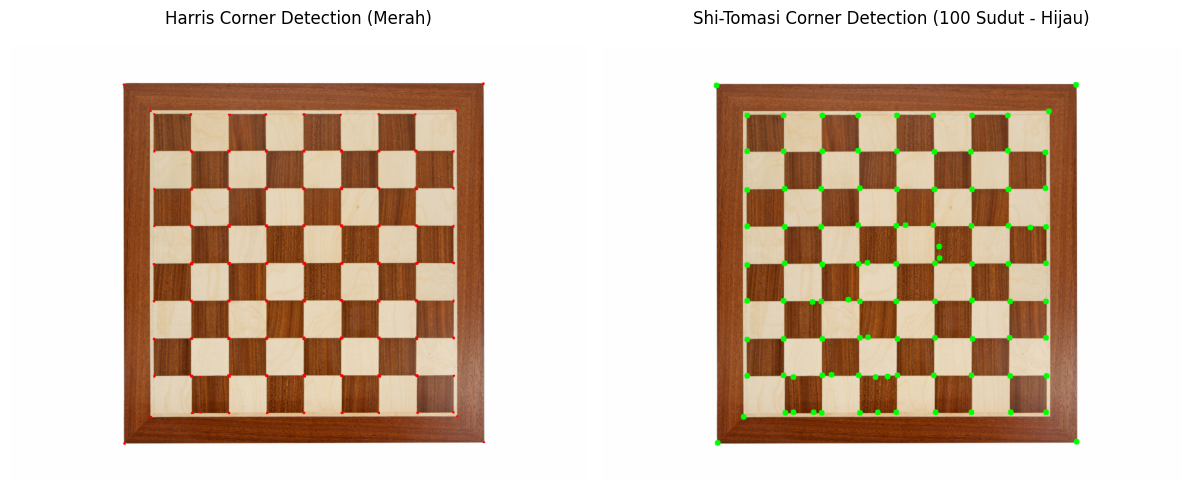

In [6]:
chess = cv.imread(PATH + 'chess-board.jpg')
chess_gray = cv.cvtColor(chess, cv.COLOR_BGR2GRAY)

# a. Harris Corner Detection
chess_float = np.float32(chess_gray)
dst = cv.cornerHarris(chess_float, blockSize=2, ksize=3, k=0.04)
dst = cv.dilate(dst, None)

chess_harris = chess.copy()
# Berikan titik merah pada sudut yang melewati threshold
chess_harris[dst > 0.01 * dst.max()] = [0, 0, 255]

# b. Shi-Tomasi Corner Detection
corners = cv.goodFeaturesToTrack(chess_gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners = np.int32(corners)

chess_shitomasi = chess.copy()
for c in corners:
    x, y = c.ravel()
    cv.circle(chess_shitomasi, (x, y), 5, (0, 255, 0), -1)

# Tampilkan perbandingan
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(chess_harris, cv.COLOR_BGR2RGB))
plt.title('Harris Corner Detection (Merah)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(chess_shitomasi, cv.COLOR_BGR2RGB))
plt.title(f'Shi-Tomasi Corner Detection ({len(corners)} Sudut - Hijau)')
plt.axis('off')

plt.tight_layout()
plt.show()

### Soal 6: Grid Detection dengan Hough Transform
Mendeteksi garis-garis grid pada gambar `sudoku.jpg` mengikuti tahapan:
1. Canny Edge Detection
2. Dilasi
3. Erosi
4. HoughLines

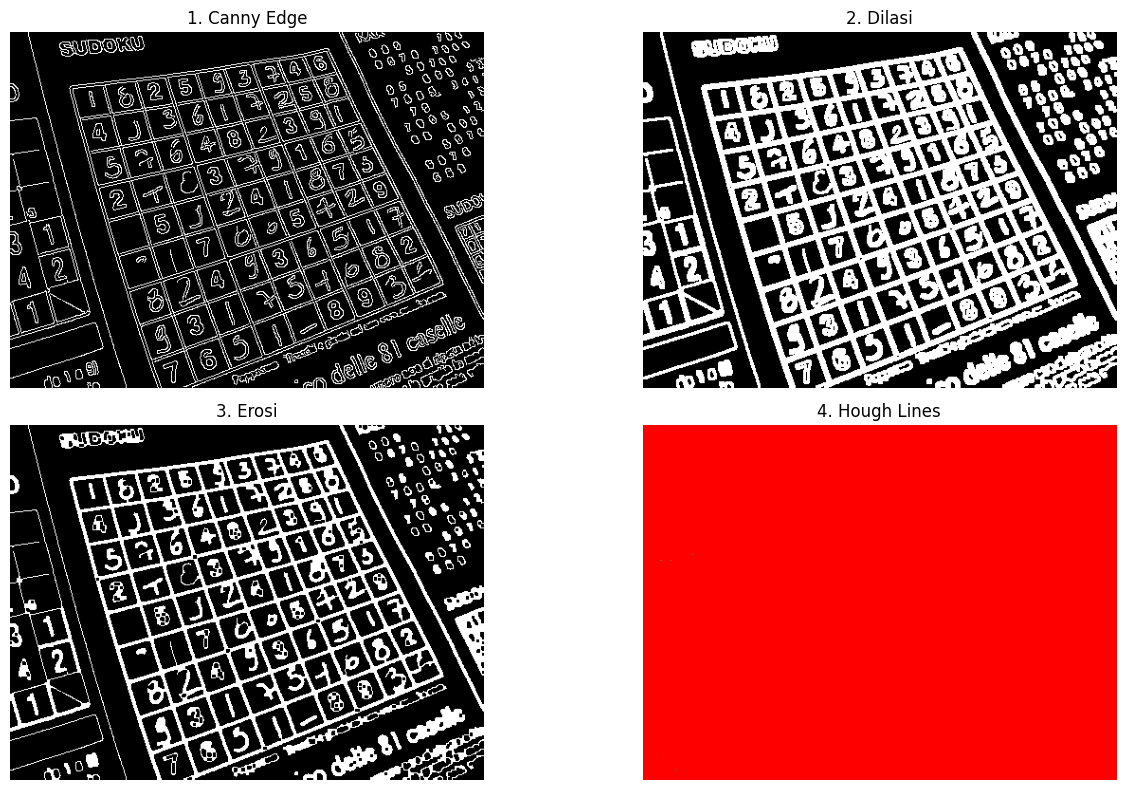

In [7]:
sudoku = cv.imread(PATH + 'sudoku.jpg')
sudoku_gray = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

# 1. Canny Edge Detection
edges = cv.Canny(sudoku_gray, 50, 150, apertureSize=3)

# 2. Dilasi
kernel = np.ones((3, 3), np.uint8)
dilasi = cv.dilate(edges, kernel, iterations=1)

# 3. Erosi
erosi = cv.erode(dilasi, kernel, iterations=1)

# 4. Deteksi garis dengan HoughLines
lines = cv.HoughLines(erosi, rho=1, theta=np.pi/180, threshold=100)

sudoku_lines = sudoku.copy()
if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)
        cv.line(sudoku_lines, (x1, y1), (x2, y2), (0, 0, 255), 1)

# Tampilkan proses dan hasil
plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1), plt.imshow(edges, cmap='gray'), plt.title('1. Canny Edge'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(dilasi, cmap='gray'), plt.title('2. Dilasi'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(erosi, cmap='gray'), plt.title('3. Erosi'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(cv.cvtColor(sudoku_lines, cv.COLOR_BGR2RGB)), plt.title('4. Hough Lines'), plt.axis('off')
plt.tight_layout()
plt.show()

### Soal 7: Contour Detection dengan `findContours()`
Mendeteksi kontur objek pada citra `laptop.jpg`.

Banyaknya kontur yang ditemukan: 48


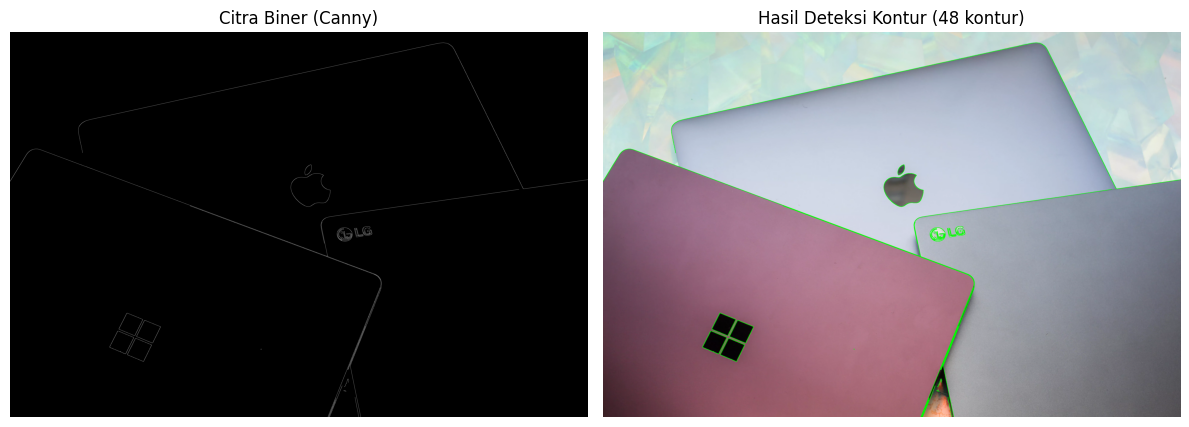

In [8]:
laptop = cv.imread(PATH + 'laptop.jpg')
laptop_gray = cv.cvtColor(laptop, cv.COLOR_BGR2GRAY)

# 1. Ubah citra ke biner menggunakan Canny
blur = cv.GaussianBlur(laptop_gray, (5, 5), 0)
thresh = cv.Canny(blur, 50, 150)

# 2. Temukan kontur
contours, hierarchy = cv.findContours(thresh, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
print(f"Banyaknya kontur yang ditemukan: {len(contours)}")

# 3. Gambar kontur pada citra
laptop_contours = laptop.copy()
cv.drawContours(laptop_contours, contours, -1, (0, 255, 0), 2)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner (Canny)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(laptop_contours, cv.COLOR_BGR2RGB))
plt.title(f'Hasil Deteksi Kontur ({len(contours)} kontur)')
plt.axis('off')

plt.tight_layout()
plt.show()

---
## D2. Praktikum Feature Matching dan Face Detection

### Soal 8: Face Detection pada Image Object Lain (`/images/facedet`)
Contoh dasar dari teori: deteksi wajah Pak Prabowo menggunakan model pre-trained Haar Cascade `haarcascade_frontalface_alt.xml`.

In [9]:
# Path XML cascade bawaan OpenCV
xml_face = cv.data.haarcascades + 'haarcascade_frontalface_alt.xml'
if not os.path.exists(xml_face):
    xml_face = cv.data.haarcascades + 'haarcascade_frontalface_default.xml'

face_cascade = cv.CascadeClassifier(xml_face)

# Baca gambar Pak Prabowo
# Cek lokasi file prabowo.jpg
prabowo_path = BASE + 'prabowo.jpg'

prabowo = cv.imread(prabowo_path)
prabowo_gray = cv.cvtColor(prabowo, cv.COLOR_BGR2GRAY)

# Deteksi wajah
faces = face_cascade.detectMultiScale(prabowo_gray, scaleFactor=1.1, minNeighbors=5)
print(f"Jumlah wajah terdeteksi: {len(faces)}")

prabowo_hasil = prabowo.copy()
for (x, y, w, h) in faces:
    cv.rectangle(prabowo_hasil, (x, y), (x + w, y + h), (255, 255, 255), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv.cvtColor(prabowo_hasil, cv.COLOR_BGR2RGB))
plt.title('Face Detection Pak Prabowo')
plt.axis('off')
plt.show()

AttributeError: module 'cv2' has no attribute 'CascadeClassifier'

Selanjutnya face detection diterapkan pada image lain di folder `facedet`: foto (Jokowi, Michael Jordan), lukisan/foto lama hitam-putih (Kartini), wajah bermasker (`mask.png`), dan foto bersama dengan banyak wajah kecil (`solvayconf.jpg`).

In [ ]:
def deteksi_wajah(img_bgr, cascade, scaleFactor=1.1, minNeighbors=5, warna=(0, 255, 0), tebal=3):
    gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    rects = cascade.detectMultiScale(gray, scaleFactor=scaleFactor, minNeighbors=minNeighbors)
    hasil = img_bgr.copy()
    for (x, y, w, h) in rects:
        cv.rectangle(hasil, (x, y), (x + w, y + h), warna, tebal)
    return hasil, rects

daftar_gambar = ['jokowi.jpg', 'kartini.jpg', 'mjordan.jpg', 'mask.png', 'solvayconf.jpg']

plt.figure(figsize=(18, 10))
for i, nama in enumerate(daftar_gambar):
    img = cv.imread(FACEDET + nama)
    tebal = 2 if nama == 'solvayconf.jpg' else 4
    hasil, rects = deteksi_wajah(img, face_cascade, 1.1, 5, tebal=tebal)
    print(f"{nama:16s}: {len(rects)} wajah terdeteksi")

    plt.subplot(2, 3, i + 1)
    plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
    plt.title(f'{nama} ({len(rects)} wajah)')
    plt.axis('off')

# Wajah kucing dengan detektor wajah manusia (untuk soal 9)
kucing = cv.imread(FACEDET + 'kucing.jpg')
hasil, rects = deteksi_wajah(kucing, face_cascade, 1.1, 5)
print(f"{'kucing.jpg':16s}: {len(rects)} wajah terdeteksi")
plt.subplot(2, 3, 6)
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.title(f'kucing.jpg ({len(rects)} wajah)')
plt.axis('off')

plt.tight_layout()
plt.show()

**Analisis:** Secara keseluruhan face detection dengan `haarcascade_frontalface_alt.xml` bekerja dengan baik: wajah pada foto berwarna (Jokowi, Michael Jordan), foto lama hitam-putih (Kartini), dan hampir seluruh wajah berukuran kecil pada foto Solvay Conference (27 wajah) berhasil terdeteksi. Pada `mask.png`, 5 dari 6 wajah terdeteksi meskipun mulut tertutup masker; satu-satunya yang gagal adalah wajah dengan **masker hitam**, karena masker gelap menutupi kontras area hidung-pipi yang menjadi fitur Haar penting. Wajah **kucing tidak terdeteksi sama sekali** (0 wajah) karena model ini hanya dilatih dengan fitur wajah manusia.

### Soal 9: Deteksi Wajah Kucing
Pada soal sebelumnya wajah kucing tidak dapat dideteksi. OpenCV ternyata sudah menyediakan pretrained feature untuk wajah kucing, yaitu `haarcascade_frontalcatface_extended.xml`.

Parameter `minSize` ditambahkan untuk membuang deteksi palsu berukuran kecil (misalnya area hidung kelinci yang mirip pola wajah kucing).

In [ ]:
cat_xml = cv.data.haarcascades + 'haarcascade_frontalcatface_extended.xml'
cat_cascade = cv.CascadeClassifier(cat_xml)
print("Cascade kucing:", os.path.basename(cat_xml), "| loaded:", not cat_cascade.empty())

def deteksi_kucing(img_bgr, minSize):
    gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    tanpa_filter = cat_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
    dengan_filter = cat_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3, minSize=minSize)
    return tanpa_filter, dengan_filter

plt.figure(figsize=(16, 9))
for row, (nama, path) in enumerate([('kucing.jpg', FACEDET + 'kucing.jpg'),
                                    ('cats_and_bunnies.jpg', PATH + 'cats_and_bunnies.jpg')]):
    img = cv.imread(path)
    raw, filt = deteksi_kucing(img, minSize=(150, 150))
    print(f"{nama:22s}: tanpa minSize = {len(raw)} deteksi, dengan minSize = {len(filt)} deteksi")

    for col, (rects, judul, warna) in enumerate([(raw, 'Tanpa minSize', (0, 0, 255)),
                                                 (filt, 'Dengan minSize=(150,150)', (0, 255, 0))]):
        hasil = img.copy()
        for (x, y, w, h) in rects:
            cv.rectangle(hasil, (x, y), (x + w, y + h), warna, 4)
        plt.subplot(2, 2, row * 2 + col + 1)
        plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
        plt.title(f'{nama} - {judul} ({len(rects)} deteksi)')
        plt.axis('off')

plt.tight_layout()
plt.show()

**Analisis:** Dengan `haarcascade_frontalcatface_extended.xml`, wajah kucing berhasil diberi rectangle. Tanpa `minSize`, detektor juga menandai area kecil yang bukan wajah kucing (hidung kucing pada `kucing.jpg` dan hidung kelinci pada `cats_and_bunnies.jpg`). Setelah ukuran minimum dibatasi, hanya wajah kucing yang tersisa.

### Soal 10: Eyes Detection pada Wajah Pak Prabowo
Menggunakan `haarcascade_eye.xml` untuk mendeteksi mata.

In [ ]:
eye_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_eye.xml')

prabowo_mata = prabowo.copy()
eyes = eye_cascade.detectMultiScale(prabowo_gray, scaleFactor=1.1, minNeighbors=5)
print(f"Jumlah mata terdeteksi: {len(eyes)}")

for (ex, ey, ew, eh) in eyes:
    cv.rectangle(prabowo_mata, (ex, ey), (ex + ew, ey + eh), (0, 255, 0), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv.cvtColor(prabowo_mata, cv.COLOR_BGR2RGB))
plt.title(f'Deteksi Mata ({len(eyes)} mata terdeteksi)')
plt.axis('off')
plt.show()

### Soal 11: Smile Detection pada Gambar People
Menggunakan `haarcascade_smile.xml` pada gambar `people.jpg` (kolase 10 wajah dari modul) dan `mjordan.jpg`. Agar mata/hidung tidak terdeteksi sebagai senyum, pencarian senyum hanya dilakukan pada **setengah bagian bawah ROI wajah** (area mulut).

In [ ]:
smile_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_smile.xml')

def deteksi_senyum(img_bgr, minNeighbors=15):
    gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    hasil = img_bgr.copy()
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)
    jumlah = 0
    for (x, y, w, h) in faces:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 0, 0), 2)
        # ROI = setengah bawah wajah (area mulut)
        y0 = y + h // 2
        roi_gray = gray[y0:y + h, x:x + w]
        smiles = smile_cascade.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=minNeighbors)
        for (sx, sy, sw, sh) in smiles:
            cv.rectangle(hasil, (x + sx, y0 + sy), (x + sx + sw, y0 + sy + sh), (0, 0, 255), 2)
            jumlah += 1
    return hasil, len(faces), jumlah

plt.figure(figsize=(18, 6))
for i, (nama, mn, lebar) in enumerate([('people.jpg', 15, 3), ('mjordan.jpg', 30, 1)]):
    hasil, n_face, n_smile = deteksi_senyum(cv.imread(FACEDET + nama), mn)
    print(f"{nama:12s}: {n_face} wajah, {n_smile} senyum terdeteksi")
    plt.subplot(1, 4, (1, 3) if i == 0 else 4)
    plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
    plt.title(f'{nama}: {n_face} wajah (biru), {n_smile} senyum (merah)')
    plt.axis('off')

plt.tight_layout()
plt.show()

**Analisis:** Pada kolase `people.jpg`, senyum hanya terdeteksi pada wajah yang benar-benar tersenyum (memperlihatkan gigi), sedangkan ekspresi lain (kaget, berpikir, datar) tidak ditandai. Membatasi ROI ke setengah bawah wajah dan memakai `minNeighbors` yang cukup tinggi efektif menekan false positive, karena `haarcascade_smile.xml` sangat mudah salah mendeteksi pola gelap-terang lain sebagai senyum. Satu wajah (yang menutupi kepala dengan tangan) tidak terdeteksi oleh face detector karena wajahnya sebagian tertutup dan miring.

### Soal 12: Face Tracking Menggunakan Google Colab
Google Colab berjalan di server cloud, sehingga `cv.VideoCapture(0)` tidak bisa mengakses webcam laptop. Solusinya (sesuai tutorial pada modul) adalah memakai **JavaScript** untuk membuka stream webcam di browser, mengirim tiap frame ke Python (base64 → array OpenCV), mendeteksi wajah dengan Haar Cascade, lalu mengirim balik **overlay bounding box** (PNG transparan) untuk ditampilkan di atas video.

> Sel di bawah dijalankan di **Google Colab**. Jika dijalankan secara lokal (Jupyter/VS Code), sel otomatis menampilkan pesan bahwa fitur ini khusus Colab. Klik video untuk menghentikan tracking.

In [ ]:
import io, html, time
from base64 import b64decode, b64encode
import PIL.Image

try:
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    DI_COLAB = True
except ImportError:
    DI_COLAB = False


def js_to_image(js_reply):
    # Konversi frame JavaScript (base64 jpeg) menjadi citra OpenCV (BGR)
    image_bytes = b64decode(js_reply.split(',')[1])
    jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
    return cv.imdecode(jpg_as_np, flags=1)


def bbox_to_bytes(bbox_array):
    # Konversi overlay bounding box (RGBA) menjadi string base64 PNG
    bbox_png = PIL.Image.fromarray(bbox_array, 'RGBA')
    buf = io.BytesIO()
    bbox_png.save(buf, format='png')
    return 'data:image/png;base64,{}'.format(str(b64encode(buf.getvalue()), 'utf-8'))


def video_stream():
    js = Javascript('''
    var video, div = null, stream, captureCanvas, imgElement, labelElement;
    var pendingResolve = null, shutdown = false;

    function removeDom() {
       stream.getVideoTracks()[0].stop();
       video.remove(); div.remove();
       video = null; div = null; stream = null;
       imgElement = null; captureCanvas = null; labelElement = null;
    }

    function onAnimationFrame() {
      if (!shutdown) { window.requestAnimationFrame(onAnimationFrame); }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8);
        }
        var lp = pendingResolve; pendingResolve = null; lp(result);
      }
    }

    async function createDom() {
      if (div !== null) { return stream; }
      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '3px';
      div.style.width = '100%';
      div.style.maxWidth = '600px';
      document.body.appendChild(div);

      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span>";
      labelElement = document.createElement('span');
      labelElement.innerText = 'No data';
      labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement);
      div.appendChild(modelOut);

      video = document.createElement('video');
      video.style.display = 'block';
      video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia({video: { facingMode: "environment"}});
      div.appendChild(video);

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute';
      imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);

      const instruction = document.createElement('div');
      instruction.innerHTML = '<span style="color: red; font-weight: bold;">Klik video untuk berhenti</span>';
      div.appendChild(instruction);
      instruction.onclick = () => { shutdown = true; };

      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640; captureCanvas.height = 480;
      window.requestAnimationFrame(onAnimationFrame);
      return stream;
    }

    async function stream_frame(label, imgData) {
      if (shutdown) { removeDom(); shutdown = false; return ''; }
      var preCreate = Date.now();
      stream = await createDom();
      var preShow = Date.now();
      if (label != "") { labelElement.innerHTML = label; }
      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }
      var preCapture = Date.now();
      var result = await new Promise(function(resolve, reject) { pendingResolve = resolve; });
      shutdown = false;
      return {'create': preShow - preCreate, 'show': preCapture - preShow,
              'capture': Date.now() - preCapture, 'img': result};
    }
    ''')
    display(js)


def video_frame(label, bbox):
    return eval_js('stream_frame("{}", "{}")'.format(label, bbox))


def face_tracking_colab():
    video_stream()
    label_html = 'Face tracking berjalan...'
    bbox = ''
    jumlah_frame = 0
    while True:
        js_reply = video_frame(label_html, bbox)
        if not js_reply:
            break
        frame = js_to_image(js_reply['img'])

        # overlay transparan 480x640 berisi bounding box wajah
        bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)
        for (x, y, w, h) in faces:
            bbox_array = cv.rectangle(bbox_array, (x, y), (x + w, y + h), (0, 255, 0), 2)
            bbox_array = cv.putText(bbox_array, 'Wajah', (x, y - 8),
                                    cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(np.uint8) * 255
        bbox = bbox_to_bytes(bbox_array)
        jumlah_frame += 1
        label_html = f'Frame {jumlah_frame} - {len(faces)} wajah terdeteksi'


if DI_COLAB:
    face_tracking_colab()
else:
    print("Face tracking webcam via JavaScript hanya dapat dijalankan di Google Colab.")
    print("Buka notebook ini di Colab lalu jalankan sel ini untuk memulai face tracking real-time.")

### Soal 13: Blurring pada Wajah yang Terdeteksi
Mengaburkan bagian wajah yang terdeteksi menggunakan fungsi `cv.medianBlur()` untuk menyamarkan identitas.

In [ ]:
prabowo_blur = prabowo.copy()

for (x, y, w, h) in faces:
    # Potong bagian wajah
    roi = prabowo_blur[y:y+h, x:x+w]
    # Terapkan median blur dengan kernel size 25
    roi_blurred = cv.medianBlur(roi, 25)
    # Masukkan kembali ke gambar asli
    prabowo_blur[y:y+h, x:x+w] = roi_blurred
    cv.rectangle(prabowo_blur, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv.cvtColor(prabowo_blur, cv.COLOR_BGR2RGB))
plt.title('Hasil Blurring Wajah (Median Blur)')
plt.axis('off')
plt.show()

### Soal 14: Mengolah Gambar KTM
a. Menampilkan foto KTM sendiri
b. Menampilkan **pas foto** dari KTM (crop otomatis: face detection → cari latar merah pas foto → crop rasio 3:4)
c. Deteksi obyek KTM pada gambar yang berisi KTM bersama barang lain menggunakan konsep **Feature Matching** (SIFT/ORB + Lowe's ratio test + Homography RANSAC)

**File yang dipakai (folder `KTM/`):**
- `foto_ktm.jpg` → foto KTM sendiri, difoto lurus (query untuk 14a, 14b, 14c)
- `ktm_*.jpg` / `ktm_*.jpeg` → foto KTM dalam kondisi berbeda / bersama barang lain (scene untuk 14c)

Jika foto scene KTM belum tersedia, 14c menjalankan demo konsep yang sama (`reeses_puffs.png` dicari pada rak `many_cereals.jpg`).

In [ ]:
import glob

def resize_max(img, max_side=1000):
    s = max_side / max(img.shape[:2])
    return cv.resize(img, None, fx=s, fy=s, interpolation=cv.INTER_AREA) if s < 1 else img

ktm_sendiri = sorted(glob.glob(KTM_DIR + 'foto_ktm.*'))
PAKAI_KTM = len(ktm_sendiri) > 0
ktm_bgr = resize_max(cv.imread(ktm_sendiri[0]), 1280) if PAKAI_KTM else None
print("KTM yang diolah:", os.path.basename(ktm_sendiri[0]) if PAKAI_KTM else "foto_ktm.jpg belum ada di folder KTM/")


def crop_pasfoto(ktm):
    # 1) deteksi wajah pada KTM
    gray = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)
    wajah = face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(ktm.shape[1] // 25,) * 2)
    if len(wajah) == 0:
        return None, None
    x, y, w, h = max(wajah, key=lambda r: r[2] * r[3])
    cx = x + w // 2

    # 2) cari area latar merah pas foto yang mengandung wajah
    hsv = cv.cvtColor(ktm, cv.COLOR_BGR2HSV)
    merah = cv.inRange(hsv, (0, 80, 60), (12, 255, 255)) | cv.inRange(hsv, (165, 80, 60), (180, 255, 255))
    merah = cv.morphologyEx(merah, cv.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    kontur, _ = cv.findContours(merah, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    for c in sorted(kontur, key=cv.contourArea, reverse=True):
        bx, by, bw, bh = cv.boundingRect(c)
        if bx < cx < bx + bw and by < y < by + bh and bw * bh > 2 * w * h:
            bh = int(bw * 4 / 3)                      # pas foto rasio 3:4 (bagian bawah = baju)
            return (bx, by, bw, min(bh, ktm.shape[0] - by)), (x, y, w, h)

    # 3) fallback: perluas kotak wajah
    bx, by = max(0, x - w // 2), max(0, y - h // 2)
    return (bx, by, 2 * w, int(2 * w * 4 / 3)), (x, y, w, h)


if PAKAI_KTM:
    kotak, wajah = crop_pasfoto(ktm_bgr)

    plt.figure(figsize=(16, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(cv.cvtColor(ktm_bgr, cv.COLOR_BGR2RGB))
    plt.title('a. Foto KTM')
    plt.axis('off')

    vis = ktm_bgr.copy()
    plt.subplot(1, 3, 2)
    if kotak is not None:
        bx, by, bw, bh = kotak
        x, y, w, h = wajah
        cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 3)
        cv.rectangle(vis, (bx, by), (bx + bw, by + bh), (255, 0, 255), 3)
    plt.imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB))
    plt.title('Wajah (hijau) & area pas foto (ungu)')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    if kotak is not None:
        plt.imshow(cv.cvtColor(ktm_bgr[by:by + bh, bx:bx + bw], cv.COLOR_BGR2RGB))
        plt.title('b. FOTO KTM')
    else:
        plt.title('b. Wajah tidak terdeteksi pada KTM')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("Upload foto_ktm.jpg ke folder KTM/ lalu jalankan ulang sel ini untuk soal 14a & 14b.")

In [ ]:
def deteksi_objek_feature(query_bgr, scene_bgr, metode='SIFT', min_match=10):
    q = cv.cvtColor(query_bgr, cv.COLOR_BGR2GRAY)
    s = cv.cvtColor(scene_bgr, cv.COLOR_BGR2GRAY)

    if metode == 'SIFT':
        detector, norm = cv.SIFT_create(), cv.NORM_L2
    else:
        detector, norm = cv.ORB_create(nfeatures=3000), cv.NORM_HAMMING

    kp1, des1 = detector.detectAndCompute(q, None)
    kp2, des2 = detector.detectAndCompute(s, None)

    # Brute-Force KNN + Lowe's ratio test
    matches = cv.BFMatcher(norm).knnMatch(des1, des2, k=2)
    good = [m for m, n in (p for p in matches if len(p) == 2) if m.distance < 0.75 * n.distance]

    hasil = scene_bgr.copy()
    inlier_mask = None
    if len(good) >= min_match:
        src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        Hm, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)
        if Hm is not None:
            h, w = q.shape
            sudut = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
            kotak = cv.perspectiveTransform(sudut, Hm)
            cv.polylines(hasil, [np.int32(kotak)], True, (0, 255, 0), 4)
            inlier_mask = mask.ravel().tolist()

    n_inlier = int(sum(inlier_mask)) if inlier_mask else 0
    vis = cv.drawMatches(query_bgr, kp1, hasil, kp2, good, None,
                         matchColor=(0, 255, 0), singlePointColor=None,
                         matchesMask=inlier_mask, flags=2)
    return vis, len(kp1), len(kp2), len(good), n_inlier


# Pasangan (query, scene) untuk soal 14c
scene_files = sorted(f for f in glob.glob(KTM_DIR + 'ktm_*.*') if f.lower().endswith(('.jpg', '.jpeg', '.png')))
if PAKAI_KTM and scene_files:
    pasangan = [(ktm_bgr, resize_max(cv.imread(f), 1000), os.path.basename(f)) for f in scene_files]
    label = 'KTM'
else:
    print("Foto KTM/scene belum ada -> demo feature matching reeses_puffs.png pada many_cereals.jpg")
    pasangan = [(resize_max(cv.imread(FACEDET + 'reeses_puffs.png'), 600),
                 cv.imread(FACEDET + 'many_cereals.jpg'), 'many_cereals.jpg')]
    label = "Reese's Puffs (demo)"

for q_img, s_img, nama_scene in pasangan:
    for metode in ['ORB', 'SIFT']:
        vis, n1, n2, n_good, n_in = deteksi_objek_feature(q_img, s_img, metode)
        print(f"{nama_scene} | {metode:4s}: keypoint query={n1}, scene={n2}, good matches={n_good}, inlier RANSAC={n_in}")
        plt.figure(figsize=(16, 6))
        plt.imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB))
        plt.title(f'c. Deteksi {label} pada {nama_scene} - {metode} + Homography ({n_in} inlier)')
        plt.axis('off')
        plt.show()

**Analisis:** Feature matching mencocokkan keypoint (titik khas) antara citra query dan citra scene. Pasangan yang ambigu dibuang dengan Lowe's ratio test (0.75), lalu Homography + RANSAC memilih pasangan yang konsisten secara geometris (inlier). Matriks homografi dipakai untuk memproyeksikan 4 sudut query ke scene sehingga lokasi objek ditandai dengan kotak hijau, meskipun objek terputar, miring, atau sebagian tertutup barang lain. SIFT umumnya menghasilkan inlier lebih banyak dan stabil, sedangkan ORB lebih cepat dengan descriptor biner (Hamming distance).

---
## D3. Tugas Pengayaan: Pengenalan Karakter KTM dengan CNN
Pada tugas pengayaan, pengenalan karakter KTM dilakukan menggunakan Deep Learning dengan arsitektur CNN (Convolutional Neural Network). Perbedaan utama CNN dengan Neural Network biasa adalah proses **Feature Extraction** pada CNN dilakukan otomatis oleh layer konvolusi (`Conv2D`) dan pooling (`MaxPooling2D`).

Tahapan:
1. **Persiapan data training**: dataset karakter `0-9` dan `A-Z` (satu subfolder per karakter) berukuran 100×100 grayscale. Dataset dibangkitkan dari beberapa font dengan augmentasi (rotasi, ketebalan, ukuran, dan **penyempitan horizontal** agar mirip font condensed pada KTM) sebagai pengganti cropping manual satu per satu. Hasil disimpan ke `X.pickle`, `Y.pickle`, `kelas.pickle`.
2. **Training** dengan arsitektur CNN sesuai modul → model `anpr.keras`.
3. **Testing**: teks KTM disegmentasi per karakter (threshold Otsu + `findContours`), disimpan di `dataset/testing/<nama>/`, lalu diprediksi.

In [ ]:
import random, pickle, shutil
import matplotlib
from PIL import Image, ImageDraw, ImageFont
from tqdm import tqdm

random.seed(42)
np.random.seed(42)

DATASET = 'dataset'
DATADIR = os.path.join(DATASET, 'training')     # satu subfolder per karakter: 0..9, A..Z
width, height = 100, 100
KARAKTER = '0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ'
N_PER_KELAS = 50

FONT_DIR = os.path.join(os.path.dirname(matplotlib.__file__), 'mpl-data', 'fonts', 'ttf')
FONT_TRAIN = ['DejaVuSans.ttf', 'DejaVuSans-Bold.ttf', 'DejaVuSans-Oblique.ttf',
              'DejaVuSansMono.ttf', 'DejaVuSansMono-Bold.ttf',
              'DejaVuSerif.ttf', 'DejaVuSerif-Bold.ttf', 'DejaVuSerif-Italic.ttf',
              'cmr10.ttf', 'cmss10.ttf', 'cmtt10.ttf']


def ke_kotak(biner_inv):
    # Crop karakter (putih di atas hitam), beri padding agar persegi, resize 100x100,
    # lalu kembalikan sebagai karakter hitam di latar putih
    ys, xs = np.where(biner_inv > 0)
    c = biner_inv[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = c.shape
    s = max(h, w) + 16
    out = np.zeros((s, s), np.uint8)
    out[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = c
    out = cv.resize(out, (width, height), interpolation=cv.INTER_AREA)
    _, out = cv.threshold(out, 127, 255, cv.THRESH_BINARY)          # binerisasi ulang setelah resize
    return 255 - out


def render_karakter(ch, font):
    f = ImageFont.truetype(os.path.join(FONT_DIR, font), random.randint(60, 90))
    im = Image.new('L', (160, 160), 0)
    ImageDraw.Draw(im).text((30, 20), ch, 255, font=f)
    a = np.array(im)
    M = cv.getRotationMatrix2D((80, 80), random.uniform(-6, 6), 1)      # augmentasi rotasi
    a = cv.warpAffine(a, M, (160, 160))
    a = cv.resize(a, None, fx=random.uniform(0.55, 1.1), fy=1)           # augmentasi lebar (font condensed seperti KTM)
    k = random.choice([0, 0, 1, 2])                                       # augmentasi ketebalan
    if k:
        a = cv.dilate(a, np.ones((k + 1, k + 1), np.uint8)) if random.random() < .5 \
            else cv.erode(a, np.ones((2, 2), np.uint8))
    a = cv.GaussianBlur(a, (3, 3), 0)
    _, a = cv.threshold(a, 100, 255, cv.THRESH_BINARY)
    return ke_kotak(a)


# Bangkitkan dataset training ke disk: dataset/training/<karakter>/<n>.png
if os.path.exists(DATADIR):
    shutil.rmtree(DATADIR)
for ch in KARAKTER:
    os.makedirs(os.path.join(DATADIR, ch), exist_ok=True)
    for i in range(N_PER_KELAS):
        cv.imwrite(os.path.join(DATADIR, ch, f'{i:03d}.png'), render_karakter(ch, random.choice(FONT_TRAIN)))

# Contoh isi dataset
plt.figure(figsize=(16, 3))
for i, ch in enumerate(KARAKTER[::3]):
    plt.subplot(1, 12, i + 1)
    plt.imshow(cv.imread(os.path.join(DATADIR, ch, '000.png'), 0), cmap='gray')
    plt.title(ch)
    plt.axis('off')
plt.suptitle('Contoh data training (100x100)')
plt.show()

In [ ]:
# Persiapan data training (sesuai kode modul)
dirs = sorted(os.listdir(DATADIR))        # daftar nama kelas
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name, disable=True):
        try:
            img_array = cv.imread(os.path.join(path, img), cv.IMREAD_GRAYSCALE)
            new_array = cv.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X,    open("X.pickle", "wb"))
pickle.dump(Y,    open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

In [ ]:
# Training data (sesuai arsitektur CNN pada modul)
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical, set_random_seed

set_random_seed(42)

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]        # diambil dari data, tidak ditulis tetap

inputs     = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten   = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

riwayat = model.fit(X, Y, epochs=20, verbose=2, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training  :", riwayat.history['accuracy'][-1])
print("akurasi validasi  :", riwayat.history['val_accuracy'][-1])

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(riwayat.history['accuracy'], label='training')
plt.plot(riwayat.history['val_accuracy'], label='validasi')
plt.title('Akurasi'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(riwayat.history['loss'], label='training')
plt.plot(riwayat.history['val_loss'], label='validasi')
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout()
plt.show()

**Persiapan data testing (karakter dari KTM).**
Baris **NIM** dan **nama** disegmentasi per karakter (threshold Otsu dengan deteksi polaritas otomatis, karena teks KTM berwarna terang di atas latar biru). Sumber yang diuji:
- `KTM/ktm_nim.jpg` & `KTM/ktm_nama.jpg` → crop manual baris NIM dan nama dari KTM sendiri, jika tersedia
- jika belum ada, baris NIM/nama disimulasikan dengan font **STIXGeneral** yang tidak dipakai saat training.

In [ ]:
DATA_TEST = os.path.join(DATASET, 'testing')
if os.path.exists(DATA_TEST):
    shutil.rmtree(DATA_TEST)

def render_baris(teks, font='STIXGeneral.ttf', ukuran=64):
    f = ImageFont.truetype(os.path.join(FONT_DIR, font), ukuran)
    im = Image.new('L', (int(ukuran * 0.75 * len(teks)) + 60, ukuran + 50), 255)
    ImageDraw.Draw(im).text((25, 15), teks, 0, font=f)
    return np.array(im)

def segmentasi_karakter(gray):
    _, biner = cv.threshold(gray, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)
    if biner.mean() > 127:          # teks terang di latar gelap -> balik polaritas
        biner = 255 - biner
    kontur, _ = cv.findContours(biner, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    kotak = [cv.boundingRect(c) for c in kontur]
    tinggi_maks = max(h for _, _, _, h in kotak)
    kotak = sorted([b for b in kotak if b[3] > 0.4 * tinggi_maks], key=lambda b: b[0])  # buang noise kecil
    return [ke_kotak(biner[y:y + h, x:x + w]) for x, y, w, h in kotak], kotak

sumber_test = {}
for nama, file_crop, teks in [('1_nim', 'ktm_nim.jpg', '254107023005'),
                              ('2_nama', 'ktm_nama.jpg', 'MOHAMMAD AL HAFIS')]:
    if os.path.exists(KTM_DIR + file_crop):
        sumber_test[nama] = (cv.imread(KTM_DIR + file_crop, 0), 'crop KTM sendiri')
    else:
        sumber_test[nama] = (render_baris(teks), 'simulasi font STIXGeneral')

plt.figure(figsize=(16, 4))
for i, (nama, (gray, asal)) in enumerate(sumber_test.items()):
    chars, kotak = segmentasi_karakter(gray)
    folder = os.path.join(DATA_TEST, nama)
    os.makedirs(folder, exist_ok=True)
    for j, c in enumerate(chars):
        cv.imwrite(os.path.join(folder, f'{j:02d}.png'), c)

    vis = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)
    for x, y, w, h in kotak:
        cv.rectangle(vis, (x, y), (x + w, y + h), (0, 0, 255), 2)
    plt.subplot(len(sumber_test), 1, i + 1)
    plt.imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB))
    plt.title(f'{nama} ({asal}) - {len(chars)} karakter tersegmentasi')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# Testing data (sesuai kode modul)
import tensorflow as tf

data_dir_testing = DATA_TEST
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs  = pickle.load(open("kelas.pickle", "rb"))   # urutan kelas saat training

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    files = sorted(os.listdir(folder))
    plt.figure(figsize=(1.2 * len(files), 1.8))
    for k, char_img in enumerate(files):
        img_array = cv.imread(os.path.join(folder, char_img), cv.IMREAD_GRAYSCALE)
        new_array = cv.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        pred = dirs[np.argmax(prediction[0])]
        temp += pred
        plt.subplot(1, len(files), k + 1)
        plt.imshow(img_array, cmap='gray')
        plt.title(pred, fontsize=14, color='blue')
        plt.axis('off')
    plt.show()
    print("folder name: {} no: {}".format(car, temp))

**Perbaikan: pembatasan kelas per field KTM.**
Field NIM pada KTM hanya berisi angka dan field nama hanya berisi huruf. Dengan informasi ini, prediksi untuk folder NIM cukup diambil dari probabilitas tertinggi di antara kelas `0-9`, dan folder nama dari kelas `A-Z`.

In [ ]:
kelas_angka = [i for i, k in enumerate(dirs) if k.isdigit()]
kelas_huruf = [i for i, k in enumerate(dirs) if k.isalpha()]

for car in sorted(os.listdir(data_dir_testing)):
    folder = os.path.join(data_dir_testing, car)
    batch = np.array([cv.resize(cv.imread(os.path.join(folder, f), 0), (width, height))
                      for f in sorted(os.listdir(folder))]).reshape(-1, width, height, 1) / 255.0
    prob = model.predict(batch, verbose=0)

    bebas = ''.join(dirs[i] for i in prob.argmax(axis=1))
    izin = kelas_angka if 'nim' in car else kelas_huruf
    terbatas = ''.join(dirs[izin[i]] for i in prob[:, izin].argmax(axis=1))
    print(f"{car:7s} | tanpa batasan: {bebas:16s} | dengan batasan field: {terbatas}")

**Analisis:** Model CNN mencapai akurasi validasi ±97% pada data training yang dibangkitkan dari beberapa font dengan augmentasi.

| Sumber uji | Tanpa batasan | Dengan batasan field | Kebenaran |
|---|---|---|---|
| NIM `254107023005` | `254107023005` | `254107023005` | ✅ |
| Nama `MOHAMMAD AL HAFIS` | `MOHAMMADALHAFIS` | `MOHAMMADALHAFIS` | ✅ (tanpa spasi) |

Kesalahan rawan terjadi pada karakter yang bentuknya mirip, seperti `1` ↔ `I`, `O` ↔ `0`, atau `T` ↔ `I`, karena CNN hanya melihat satu karakter tanpa konteks. Dua langkah dipakai untuk mengatasinya: (1) **augmentasi penyempitan horizontal** saat membuat data training, agar model mengenali font condensed yang dipakai pada KTM; (2) **pembatasan kelas per field** (NIM hanya `0-9`, nama hanya `A-Z`), yang menghapus kesalahan lintas angka-huruf. Spasi antarkata tidak ikut terbaca karena segmentasi hanya mengambil kontur karakter. Akurasi pada foto KTM asli dapat ditingkatkan dengan menambahkan potongan karakter dari KTM sendiri ke dataset training (crop manual satu per satu, sesuai saran modul).